#Logistic Regression, Digit Classification


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import datasets, preprocessing, linear_model
from sklearn.model_selection import train_test_split

In [12]:
data = datasets.load_digits(n_class=2)

In [13]:
X = data['data']
y = data['target']

print("shape of X =", X.shape)
print("shape of y =", y.shape)
print("feature names:", data["feature_names"])

shape of X = (360, 64)
shape of y = (360,)
feature names: ['pixel_0_0', 'pixel_0_1', 'pixel_0_2', 'pixel_0_3', 'pixel_0_4', 'pixel_0_5', 'pixel_0_6', 'pixel_0_7', 'pixel_1_0', 'pixel_1_1', 'pixel_1_2', 'pixel_1_3', 'pixel_1_4', 'pixel_1_5', 'pixel_1_6', 'pixel_1_7', 'pixel_2_0', 'pixel_2_1', 'pixel_2_2', 'pixel_2_3', 'pixel_2_4', 'pixel_2_5', 'pixel_2_6', 'pixel_2_7', 'pixel_3_0', 'pixel_3_1', 'pixel_3_2', 'pixel_3_3', 'pixel_3_4', 'pixel_3_5', 'pixel_3_6', 'pixel_3_7', 'pixel_4_0', 'pixel_4_1', 'pixel_4_2', 'pixel_4_3', 'pixel_4_4', 'pixel_4_5', 'pixel_4_6', 'pixel_4_7', 'pixel_5_0', 'pixel_5_1', 'pixel_5_2', 'pixel_5_3', 'pixel_5_4', 'pixel_5_5', 'pixel_5_6', 'pixel_5_7', 'pixel_6_0', 'pixel_6_1', 'pixel_6_2', 'pixel_6_3', 'pixel_6_4', 'pixel_6_5', 'pixel_6_6', 'pixel_6_7', 'pixel_7_0', 'pixel_7_1', 'pixel_7_2', 'pixel_7_3', 'pixel_7_4', 'pixel_7_5', 'pixel_7_6', 'pixel_7_7']


In [14]:
df = pd.DataFrame(X, columns=data["feature_names"])
df.head()

,pixel_0_0,pixel_0_1,pixel_0_2,pixel_0_3,pixel_0_4,pixel_0_5,pixel_0_6,pixel_0_7,pixel_1_0,pixel_1_1,...,pixel_6_6,pixel_6_7,pixel_7_0,pixel_7_1,pixel_7_2,pixel_7_3,pixel_7_4,pixel_7_5,pixel_7_6,pixel_7_7
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0
2,0.0,0.0,1.0,9.0,15.0,11.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,10.0,13.0,3.0,0.0,0.0
3,0.0,0.0,0.0,0.0,14.0,13.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,13.0,16.0,1.0,0.0
4,0.0,0.0,3.0,13.0,11.0,7.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,2.0,12.0,13.0,4.0,0.0,0.0


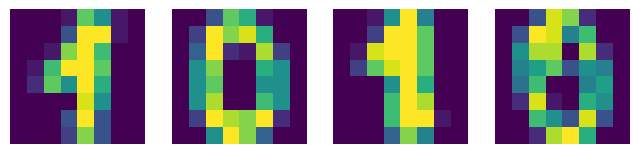

In [15]:
import random
from skimage import io

random.seed(382)
plt.figure(figsize=(8,8))
for i, img in enumerate(random.choices(data["images"], k=4)):
    plt.subplot(1, 4, i+1)
    plt.imshow(img)
    plt.axis("off")

plt.show()

In [16]:
# Normalize the dataset to the range [0,1]
X_norm = preprocessing.normalize(X)

# Convert the normalized data to a dataframe
df = pd.DataFrame(X_norm)

# Visualize the first 10 rows of the dataframe
display(df.head(10))

,0,1,2,3,4,5,6,7,8,9,...,54,55,56,57,58,59,60,61,62,63
0,0.0,0.0,0.090240,0.234625,0.162433,0.018048,0.000000,0.0,0.0,0.000000,...,0.000000,0.0,0.0,0.0,0.108288,0.234625,0.180481,0.000000,0.000000,0.0
1,0.0,0.0,0.000000,0.184966,0.200380,0.077069,0.000000,0.0,0.0,0.000000,...,0.000000,0.0,0.0,0.0,0.000000,0.169552,0.246621,0.154138,0.000000,0.0
2,0.0,0.0,0.016621,0.149585,0.249308,0.182826,0.000000,0.0,0.0,0.000000,...,0.000000,0.0,0.0,0.0,0.016621,0.166206,0.216067,0.049862,0.000000,0.0
3,0.0,0.0,0.000000,0.000000,0.212341,0.197173,0.015167,0.0,0.0,0.000000,...,0.000000,0.0,0.0,0.0,0.000000,0.015167,0.197173,0.242675,0.015167,0.0
4,0.0,0.0,0.046341,0.200810,0.169916,0.108128,0.000000,0.0,0.0,0.000000,...,0.015447,0.0,0.0,0.0,0.030894,0.185363,0.200810,0.061788,0.000000,0.0
5,0.0,0.0,0.000000,0.029683,0.237461,0.237461,0.029683,0.0,0.0,0.000000,...,0.029683,0.0,0.0,0.0,0.000000,0.029683,0.178096,0.222620,0.059365,0.0
6,0.0,0.0,0.153393,0.214750,0.168732,0.046018,0.000000,0.0,0.0,0.061357,...,0.000000,0.0,0.0,0.0,0.168732,0.245429,0.184072,0.046018,0.000000,0.0
7,0.0,0.0,0.091745,0.214071,0.152908,0.030582,0.000000,0.0,0.0,0.000000,...,0.000000,0.0,0.0,0.0,0.107036,0.244653,0.168199,0.015291,0.000000,0.0
8,0.0,0.0,0.000000,0.000000,0.207452,0.086438,0.000000,0.0,0.0,0.000000,...,0.000000,0.0,0.0,0.0,0.000000,0.051863,0.276603,0.138302,0.000000,0.0
9,0.0,0.0,0.000000,0.017487,0.192362,0.157387,0.000000,0.0,0.0,0.000000,...,0.000000,0.0,0.0,0.0,0.000000,0.034975,0.244824,0.104925,0.000000,0.0


In [17]:
# Split the normalized datasets (train, test by 80:20 ratio)
X_train, X_test, y_train, y_test = train_test_split(X_norm, y, test_size=0.2, random_state=42)

In [18]:
# Define the model
model = linear_model.LogisticRegression()

# Train the model
model = model.fit(X_train,y_train)

# Predict y_train
y_train_predict = model.predict(X_train)

# Predict y_test
y_test_predict = model.predict(X_test)

acc_training = np.mean(y_train == y_train_predict)*100
acc_testing = np.mean(y_test == y_test_predict)*100
print("Training accuracy (%) =", acc_training)
print("Testing accuracy (%) =", acc_testing)

Training accuracy (%) = 100.0
Testing accuracy (%) = 100.0
